# Structure & Practice — can we detect cataloguing practice at scale? (v1)

**The hypothesis is not in doubt.** Cataloguers work to standards. They learn
conventions from predecessors and colleagues, and they pass them on. Practice is
transmitted. What the field lacks is a *computational* method that can approximate
that transmission **at scale**, across heterogeneous catalogue data, without being
told in advance where the boundaries lie.

**This notebook is that method, as a test case for the article.** It asks how far
a deliberately simple, transparent pipeline can go toward surfacing shared practice:

1. strip boilerplate; segment records into clauses;
2. describe each clause by **content-agnostic structural features only**;
3. cluster clauses into **data-driven** categories (no per-collection rules), so a
   record becomes a *sequence* and a *profile* of structural moves;
4. **cluster records by those profiles — blind to which collection they come from**
   — using HDBSCAN, which is allowed to leave records unclustered. We are *not*
   forcing every record into a group; the amount that does not cluster is itself a
   result;
5. read the clusters: which structural practices recur, and crucially **which ones
   cut across collections** — practice that travels independently of subject matter
   or medium is the computational shadow of the transmission we know happens.

Collection is used here only as a *post-hoc lens* to ask whether a practice cluster
is collection-bound or collection-crossing. It is never an input to the clustering.

Supersedes the collection-keyed masked attempt in `attic/`. Rationale:
`research-notes/2026-06-18_NLS-merged-corpus_analysis-notes.md` (Renewal 2026-06-22).
Following van Strien, category quality must be judged on a labelled
sample (Steps 3 & 4 surface the material); the notebook asserts no accuracy it has
not measured, and reports where the method falls short (Step 11).

## Configuration
Everything tunable lives here.

In [1]:
from pathlib import Path
import random, time
import numpy as np
import pandas as pd

CODE_DIR   = Path.cwd()
import sys; sys.path.insert(0, str(CODE_DIR.parent))   # parent holds structural_masking_v1.py
DATA_DIR   = CODE_DIR / ".." / ".." / ".." / "data"
CORPUS_XML = DATA_DIR / "nls-merged-corpus" / "nls-merged-corpus-v2.xml"
DERIVED    = CODE_DIR / "derived-data"; DERIVED.mkdir(exist_ok=True)
VIS        = CODE_DIR / "visualisations"; VIS.mkdir(exist_ok=True)

RANDOM_SEED = 42
random.seed(RANDOM_SEED); np.random.seed(RANDOM_SEED)

# categoriser
K            = 10
K_CANDIDATES = (8, 10, 12, 14)
FIT_PER_COLL = 300        # records/collection sampled to DERIVE categories

# practice clustering (collection-BLIND)
SAMPLE_CAP_PER_COLL = 150 # records/collection in the analysis sample (ensures the
                          #   small collections appear; clustering itself is blind)
MIN_CLUSTER_SIZE    = 30  # HDBSCAN: smallest admissible practice cluster
MIN_SAMPLES         = 10   # HDBSCAN: conservativeness (higher => more noise)
SM_SUBSAMPLE        = 300  # records for the (slower) SM sequence-distance panel
N_PERMUTATIONS      = 1000

pd.set_option("display.max_colwidth", 70)
pd.set_option("display.width", 160)
TS = time.strftime("%Y%m%d-%H%M%S") + "_mcs30-ms10"
print("Corpus:", CORPUS_XML.resolve()); print("Run:", TS)

Corpus: data/nls-merged-corpus/nls-merged-corpus-v2.xml
Run: 20260623-172920_mcs30-ms10


## Step 1 — Load the merged corpus
Streaming parse; validate after load.

In [2]:
import xml.etree.ElementTree as ET
from collections import Counter
import structural_masking_v1 as sm

NS = {"mc": "http://purl.org/nls-merged-corpus/1.0/"}
def load_records(path):
    recs = []
    for _, d in ET.iterparse(str(path), events=("end",)):
        if not d.tag.endswith("Description"): continue
        descs = [e.text for e in d if e.tag.endswith("description") and e.text]
        nsub  = sum(1 for e in d if e.tag.endswith("subject"))
        coll  = d.find("mc:collection", NS); rid = d.find("mc:record_id", NS)
        recs.append({"record_id": rid.text if rid is not None else "?",
                     "collection": coll.text if coll is not None else "?",
                     "descriptions": descs, "n_subjects": nsub})
        d.clear()
    return recs

t0 = time.time(); records = load_records(CORPUS_XML)
assert records, f"No records parsed from {CORPUS_XML}"
print(f"Loaded {len(records):,} records in {time.time()-t0:.1f}s")
pd.Series(Counter(r["collection"] for r in records)).sort_values(ascending=False).to_frame("records")

Loaded 26,957 records in 1.3s


,records
mia,23491
eb,2438
hd,537
tp,190
tb,91
sp,72
jw,62
fb,40
jk,23
ja,13


## Step 2 — Derive the structural categories (data-driven)

Cluster clauses by content-agnostic structure into `K` categories. `K` is chosen by
silhouette, not by hand; seed-stability (ARI) reports reproducibility.

In [3]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, adjusted_rand_score, adjusted_mutual_info_score

by_coll = {}
for i, r in enumerate(records):
    if sm.segment_record(r["descriptions"]):
        by_coll.setdefault(r["collection"], []).append(i)
fit_idx = []
for cl, idxs in by_coll.items():
    random.shuffle(idxs); fit_idx.extend(idxs[:FIT_PER_COLL])
clause_rec, clauses = [], []
for i in fit_idx:
    for c in sm.segment_record(records[i]["descriptions"]):
        clause_rec.append(i); clauses.append(c)
X = np.vstack([sm.clause_features(c) for c in clauses])
Xs = StandardScaler().fit_transform(X)
sil = {k: silhouette_score(Xs[:6000],
        KMeans(n_clusters=k, random_state=RANDOM_SEED, n_init=5).fit_predict(Xs)[:6000])
       for k in K_CANDIDATES}
print(f"Fit on {len(fit_idx):,} records -> {len(clauses):,} clauses")
print("Silhouette by K:", {k: round(v,3) for k,v in sil.items()}, f"  (using K={K})")
cat = sm.StructuralCategoriser(k=K, random_seed=RANDOM_SEED).fit(clauses)
a = KMeans(n_clusters=K, random_state=1, n_init=5).fit_predict(Xs)
b = KMeans(n_clusters=K, random_state=2, n_init=5).fit_predict(Xs)
print(f"Seed-stability ARI (K={K}): {adjusted_rand_score(a,b):.3f}")

Fit on 1,391 records -> 7,946 clauses
Silhouette by K: {8: 0.466, 10: 0.442, 12: 0.436, 14: 0.38}   (using K=10)
Seed-stability ARI (K=10): 0.991


## Step 3 — The category codebook (PI-validated) and collection-independence

Each category now carries the **PI's validated label and verdict** from the eyeball
workbook (`structural_masking_v1.VALIDATED_LABELS`): what the category captures,
whether it is coherent, and whether it was flagged as greedy. We also check
`AMI(category, collection)` — near 0 means categories are independent of collection
(good); near 1 means they are collection proxies (the old failure).

In [4]:
clab = [cat.predict_clause(c) for c in clauses]
clab_c = [sm.consolidate(l) for l in clab]            # consolidated v2 labels
ccol = [records[i]["collection"] for i in clause_rec]
ami  = adjusted_mutual_info_score(ccol, clab_c)
print(f"AMI(category, collection) = {ami:.3f}   (0 = collection-independent; 1 = proxy)")

desc = cat.describe_categories()                       # keyed by raw CAT_xx
from collections import defaultdict as _dd
_raw_for = _dd(list)
for _raw in cat.labels_:
    _raw_for[sm.consolidate(_raw)].append(_raw)
rows = []
for l in sm.CONSOLIDATED_ORDER:
    ex = [clauses[j] for j,x in enumerate(clab_c) if x==l][:1]
    v = sm.VALIDATED_LABELS_V2.get(l, {})
    feats = ", ".join(dict.fromkeys(f for _raw in _raw_for[l] for f in desc[_raw]))
    rows.append({"category": l, "label": v.get("label",""), "captures": v.get("captures",""),
                 "coherent": v.get("coherent",""), "greedy": v.get("greedy",""),
                 "n_clauses": clab_c.count(l),
                 "distinguishing_features": feats,
                 "example": (ex[0][:80] if ex else "")})
cat_table = pd.DataFrame(rows)
# persist the validated codebook
cat_table.to_csv(DERIVED / f"structure-codebook_nls-merged-corpus_{TS}.tsv",
                 sep="\t", index=False)
cat_table

AMI(category, collection) = 0.269   (0 = collection-independent; 1 = proxy)


,category,label,captures,coherent,greedy,n_clauses,distinguishing_features,example
0,CAT_00,opening (terse / stub),terse opening: bare publication-date stub or very short opening (W...,Yes,No,1204,"titlecase_token_ratio+, alpha_token_ratio+, starts_with_digit-, co...",Three ballads.
1,CAT_01,shotlist,a part of a shotlist,Yes,No,646,"upper_char_ratio+, starts_with_digit+, log_n_tokens+, colon_per_to...",SHOTLIST: 00:00:10 00:04:10 29/06/1989 OPENING OF PARLIAMENT - INT...
2,CAT_02,direction-to-reader,direction to the reader to focus on one part of the object,Yes,No,309,"period_per_token+, mean_token_len-, log_n_tokens-, alpha_token_ratio+",In one column..
3,CAT_03,genre,"genres, separated by semi-colons",Yes,No,132,"semicolon_per_token+, mean_token_len+, function_word_ratio-, perio...",non-fiction; newsreel
4,CAT_04,location,mostly places,Partly,No,567,"comma_per_token+, titlecase_token_ratio+, alpha_token_ratio+, star...","Dismal = Daniel Finch, Earl of Nottingham."
5,CAT_05,descriptive shotlist,a shotlist part that includes interpretation and context,Partly,No,552,"n_timecodes_log+, has_timecode+, bracket_per_token+, log_n_tokens+",SHOTLIST: gvs of woman at the Workers Education Association (WEA) ...
6,CAT_07,date,date in yyyy format,Yes,No,66,"digit_char_ratio+, starts_with_digit+, alpha_token_ratio-, log_n_t...",1840.
7,CAT_08,opening (descriptive),fuller opening prose: discursive item description or quoted-text i...,Yes,"Partly (broad, but distinct from CAT_00)",3829,"function_word_ratio+, log_n_tokens+, alpha_token_ratio+, bracket_p...",The text mentions the census taking place on Sunday April 3rd - 18...
8,CAT_09,closing,what seems to be the end of a catalogue entry,Partly,No,476,"colon_per_token+, period_per_token-, starts_with_digit-, bracket_p...",Tune: - Vilikins and his Dinah.
9,CAT_OTHER,other / unreliable,"PI judged incoherent (was CAT_06); isolated, not interpreted",No,No,165,"dash_per_token+, mean_token_len+, alpha_token_ratio-, log_n_tokens-",T--l--nd = John Toland.


### Category share within each collection

If the same categories recur across collections (columns co-populated, not block-
diagonal), the structural vocabulary is genuinely shared — the precondition for
finding cross-collection practice.

In [5]:
share = (pd.crosstab(pd.Series(ccol, name="collection"),
                       pd.Series(clab_c, name="category"), normalize="index")
           .reindex(columns=sm.CONSOLIDATED_ORDER).fillna(0).round(2))
share.rename(columns=sm.label_v2)

category,opening (terse / stub),shotlist,direction-to-reader,genre,location,descriptive shotlist,date,opening (descriptive),closing,other / unreliable
collection,,,,,,,,,,
eb,0.15,0.00,0.09,0.00,0.01,0.00,0.00,0.72,0.02,0.00
fb,0.01,0.00,0.00,0.00,0.13,0.00,0.01,0.85,0.00,0.00
hd,0.03,0.00,0.01,0.00,0.03,0.00,0.00,0.93,0.00,0.00
ja,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
jk,0.28,0.00,0.00,0.00,0.00,0.00,0.44,0.28,0.00,0.00
jw,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
mia,0.18,0.19,0.03,0.04,0.07,0.16,0.00,0.25,0.02,0.05
sp,0.09,0.00,0.01,0.00,0.00,0.00,0.00,0.41,0.49,0.00
tb,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.50,0.50,0.00


### Category review from the PI eyeball — agenda for the next iteration

These are the issues the PI flagged. They are **not applied automatically**: the
eyeball (categories *and* cluster exemplars) was done against the current
categories, so re-clustering now would invalidate that validation. They are the
agenda for the next pipeline iteration (with a sensitivity sweep). The diagnostic
below opens up the greedy "opening" category (CAT_08) so its internal variety is
visible before any split.

In [6]:
for note in sm.CATEGORY_REVIEW_NOTES:
    print(" -", note)

# Diagnostic: sub-cluster the greedy CAT_08 ("opening (broad)") to expose what it conflates.
greedy_id = "CAT_08"
gi = [j for j,x in enumerate(clab) if x==greedy_id]
if len(gi) >= 20:
    from sklearn.cluster import KMeans as _KM
    Xg = StandardScaler().fit_transform(np.vstack([sm.clause_features(clauses[j]) for j in gi]))
    sub = _KM(n_clusters=4, random_state=RANDOM_SEED, n_init=5).fit_predict(Xg)
    print(f"\n{greedy_id} ('{sm.label_of(greedy_id)}') holds {len(gi)} clauses; "
          f"sub-clustered into 4 to show its internal variety:")
    for s in range(4):
        members = [gi[k] for k in range(len(gi)) if sub[k]==s]
        exs = [clauses[m][:70] for m in members[:2]]
        print(f"  sub {s}: n={len(members)} | e.g. " + " || ".join(exs))
else:
    print(f"\n{greedy_id} has too few clauses in this sample to sub-cluster.")

 - CAT_00 ~ CAT_08: both labelled 'opening' by the PI -> merge candidate (redundant split).
 - CAT_08: flagged greedy (absorbs distinct moves).
 - CAT_06: judged incoherent ('not sure') -> low-confidence; assignments unreliable.
 - RUN 2 (K=14) tested and rejected — see comment above; K=10 retained; cross-collection finding robust across K.
 - RUN 3 (2026-06-23): opening merge REVERSED after eyeball — CAT_00 (stub) vs CAT_08 (descriptive) are a real distinction; only CAT_06 -> CAT_OTHER.

CAT_08 ('opening (broad)') holds 3829 clauses; sub-clustered into 4 to show its internal variety:
  sub 0: n=1061 | e.g. In one column with a woodcut above the title.. || In two columns with an etching above the title.
  sub 1: n=517 | e.g. The text mentions the census taking place on Sunday April 3rd - 1881 i || Attempts were made in both 1857 and successfully in 1858.
  sub 2: n=480 | e.g. First line reads: Oh, pay attention old and young.. || The ship Niagara - first line reads: Hail! stately Niaga

## Step 4 — See the masking in action

A few records, blind to collection: original description -> masked sequence of
structural moves -> profile. This is what every downstream comparison "sees".

In [7]:
demo_idx = random.sample([i for v in by_coll.values() for i in v], 10)
rows = []
for i in demo_idx:
    seq = cat.mask_record(records[i]["descriptions"])
    orig = sm.strip_boilerplate(" ".join(records[i]["descriptions"]))
    rows.append({"collection": records[i]["collection"],
                 "original (truncated)": orig[:90],
                 "masked sequence": " ".join(seq)[:70]})
pd.DataFrame(rows)

,collection,original (truncated),masked sequence
0,mia,"non-fiction; sponsored Director, Donald Blakey ; Producer, Zaar In...",CAT_03 CAT_04 CAT_08 CAT_02 CAT_08 CAT_05
1,mia,non-fiction [filmed by Mr Durning. Teacher's record of underprivil...,CAT_06 CAT_00 CAT_08
2,mia,"non-fiction; television documentary Producer, Scottish Television....",CAT_03 CAT_04 CAT_08 CAT_09 CAT_00 CAT_08 CAT_05 CAT_08 CAT_05
3,mia,non-fiction; amateur Amateur footage of a cruise on the Firth of C...,CAT_03 CAT_08 CAT_05
4,eb,First line reads: You sons of Albion take up your arms. Dated from...,CAT_08
5,mia,non-fiction A compilation tape featuring news items from Grampian ...,CAT_06 CAT_08 CAT_01
6,mia,"fiction Director, Nigel Atkinson & Huw Davies ; Producer, Cliffhan...",CAT_00 CAT_04 CAT_00 CAT_04 CAT_00 CAT_04 CAT_00 CAT_08
7,mia,non-fiction; television arts Coverage of the 2008 Royal National M...,CAT_03 CAT_00
8,mia,non-fiction; technical Cunard White Star liner Ship No. 552. Gener...,CAT_03 CAT_00 CAT_07 CAT_00 CAT_08 CAT_07 CAT_00 CAT_07 CAT_02 CAT...
9,mia,fiction Children's animated drama series. Episode 18 SHOTLIST: Tha...,CAT_00 CAT_08


## Step 5 — Mask every record (sequence + profile)

Batched (one prediction pass over all clauses). Saved for reuse.

In [8]:
segs = [sm.segment_record(r["descriptions"]) for r in records]
flat = [c for s in segs for c in s]
t0 = time.time(); pred = cat.predict_clauses(flat)
masked = {}; pos = 0; rows = []
for i, s in enumerate(segs):
    ids = pred[pos:pos+len(s)]; pos += len(s)
    seq = []
    for c in ids:
        l = sm.consolidate(cat.label_for(int(c)))
        if not seq or seq[-1] != l: seq.append(l)
    counts_raw = np.bincount(ids, minlength=K).astype(float) if len(ids) else np.zeros(K)
    counts = sm.consolidate_profile(counts_raw)            # length-9 v2 profile
    share_v = counts/counts.sum() if counts.sum() else counts
    masked[i] = {"collection": records[i]["collection"], "seq": seq,
                 "share": share_v, "n": int(counts.sum())}
    rows.append([records[i]["record_id"], records[i]["collection"], int(counts.sum()),
                 " ".join(seq)] + [f"{x:.4f}" for x in share_v])
cols = ["record_id","collection","n_clauses","sequence"]+[f"share_{l}" for l in sm.CONSOLIDATED_ORDER]
pd.DataFrame(rows, columns=cols).to_csv(
    DERIVED / f"structure-features_nls-merged-corpus_{TS}.tsv", sep="\t", index=False)
print(f"Masked {len(records):,} records in {time.time()-t0:.0f}s "
      f"({sum(1 for m in masked.values() if not m['seq'])} had no maskable content)")

Masked 26,957 records in 6s (158 had no maskable content)


## Step 6 — Cluster records by practice, blind to collection

Draw a sample (capped per collection so the small collections are represented — a
sampling choice, not an analytical one), compute pairwise **Jensen–Shannon
divergence** between profiles, and cluster with **HDBSCAN**. HDBSCAN is chosen on
purpose: it finds dense groups of similar practice and labels the rest `-1` (noise).
We do not force structure that is not there — the noise fraction is reported.

In [9]:
from scipy.spatial.distance import pdist, squareform
from sklearn.cluster import HDBSCAN

samp = []
for cl, idxs in by_coll.items():
    samp.extend([i for i in idxs[:SAMPLE_CAP_PER_COLL] if masked[i]["seq"]])
samp = sorted(set(samp))
P = np.vstack([masked[i]["share"] for i in samp])
D = squareform(pdist(P, metric="jensenshannon"))     # JS distance matrix
D[np.isnan(D)] = 0.0
hdb = HDBSCAN(min_cluster_size=MIN_CLUSTER_SIZE, min_samples=MIN_SAMPLES,
              metric="precomputed").fit(D)
labels = hdb.labels_
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
noise = float(np.mean(labels == -1))
print(f"Sample: {len(samp)} records | practice clusters found: {n_clusters} | "
      f"unclustered (noise): {noise:.0%}")

Sample: 901 records | practice clusters found: 6 | unclustered (noise): 29%


/home/jwbaker/miniforge3/envs/dh-soton/lib/python3.11/site-packages/sklearn/cluster/_hdbscan/hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


## Step 7 — Characterise each practice cluster

For every cluster: size, how many collections it spans, whether it is
**collection-crossing**, its dominant structural categories, and an exemplar. Sorted
by size.

In [10]:
def top_cats(idx_list, n=3):
    m = np.mean([masked[i]["share"] for i in idx_list], axis=0)
    return ", ".join(f"{sm.label_v2(sm.CONSOLIDATED_ORDER[j])}({m[j]:.2f})" for j in np.argsort(-m)[:n])

rows = []
for lab in sorted(set(labels)):
    members = [samp[j] for j in range(len(samp)) if labels[j]==lab]
    colls = Counter(records[i]["collection"] for i in members)
    ex_i = members[0]
    rows.append({"cluster": ("noise" if lab==-1 else f"P{lab}"),
                 "size": len(members), "n_collections": len(colls),
                 "cross_collection": "" if lab==-1 else ("YES" if len(colls)>1 else "no"),
                 "collections": ", ".join(f"{c}:{n}" for c,n in colls.most_common()),
                 "dominant_categories": top_cats(members),
                 "exemplar_sequence": " ".join(masked[ex_i]["seq"])[:55]})
practice = pd.DataFrame(rows).sort_values("size", ascending=False).reset_index(drop=True)
practice.to_csv(DERIVED / f"practice-clusters_nls-merged-corpus_{TS}.tsv", sep="\t", index=False)
practice

,cluster,size,n_collections,cross_collection,collections,dominant_categories,exemplar_sequence
0,noise,260,7,,"mia:142, eb:46, tp:29, jk:23, hd:14, fb:3, sp:3","opening (descriptive)(0.32), opening (terse / stub)(0.17), locatio...",CAT_08 CAT_02
1,P2,173,6,YES,"tb:91, sp:57, tp:18, eb:4, hd:2, mia:1","opening (descriptive)(0.51), closing(0.49), opening (terse / stub)...",CAT_08 CAT_09
2,P4,167,3,YES,"hd:99, eb:67, fb:1","opening (descriptive)(1.00), opening (terse / stub)(0.00), shotlis...",CAT_08
3,P1,116,3,YES,"tp:103, sp:12, mia:1","opening (terse / stub)(0.39), closing(0.26), location(0.21)",CAT_03 CAT_04 CAT_09 CAT_02 CAT_00 CAT_02 CAT_00 CAT_08
4,P0,78,3,YES,"jw:62, ja:13, eb:3","opening (terse / stub)(1.00), shotlist(0.00), direction-to-reader(...",CAT_00
5,P3,55,3,YES,"eb:30, hd:19, mia:6","opening (descriptive)(0.71), opening (terse / stub)(0.29), other /...",CAT_00 CAT_08 CAT_00
6,P5,52,2,YES,"fb:36, hd:16","opening (descriptive)(0.84), location(0.16), opening (terse / stub...",CAT_08 CAT_04


## Step 8 — Cross-collection practice (the point of the exercise)

The clusters that span more than one collection are the candidates for transmitted
practice that travels independently of subject and medium. Here are exemplars from
*different* collections that the method placed in the **same** practice cluster.

In [11]:
cross = [lab for lab in sorted(set(labels)) if lab!=-1 and
         len(set(records[samp[j]]["collection"] for j in range(len(samp)) if labels[j]==lab))>1]
rows = []
for lab in cross[:6]:
    members = [samp[j] for j in range(len(samp)) if labels[j]==lab]
    seen = set()
    for i in members:
        c = records[i]["collection"]
        if c in seen: continue
        seen.add(c)
        rows.append({"cluster": f"P{lab}", "collection": c,
                     "masked sequence": " ".join(masked[i]["seq"])[:45],
                     "original (truncated)": sm.strip_boilerplate(" ".join(records[i]["descriptions"]))[:75]})
print(f"{len(cross)} of {n_clusters} practice clusters are collection-crossing.")
pd.DataFrame(rows)

6 of 6 practice clusters are collection-crossing.


,cluster,collection,masked sequence,original (truncated)
0,P0,eb,CAT_00,Woodcut on title page..
1,P0,ja,CAT_00,Originally Published 1682
2,P0,jw,CAT_00,Originally Published 1828
3,P1,mia,CAT_03 CAT_04 CAT_09 CAT_02 CAT_00 CAT_02 CAT,"non-fiction; television educational Director, Alan Wallis ; Produc..."
4,P1,sp,CAT_09 CAT_00,Date of event depicted: between 1917 and 1936 Coloured photomontag...
5,P1,tp,CAT_09 CAT_00,Originally published: 1868 Actress in dancing costume..
6,P2,eb,CAT_08 CAT_09,First line reads: When on Ramillies' bloody field. In two columns ...
7,P2,hd,CAT_08 CAT_07 CAT_08,"This sketch shows Carnwath Collegiate Church, Lanarkshire, and a n..."
8,P2,mia,CAT_OTHER CAT_08 CAT_00 CAT_08 CAT_00,non-fiction Gardening delights with presenting duo Calina and Eili...
9,P2,sp,CAT_09 CAT_08,Date of event depicted: between 1917 and 1921 Date of event depict...


## Step 9 — Map the practice space
Classical MDS of the JS-distance matrix. Same points, coloured two ways: by practice cluster, then by collection. If clusters (left) do not line up with collections (right), practice is cutting across collection lines.

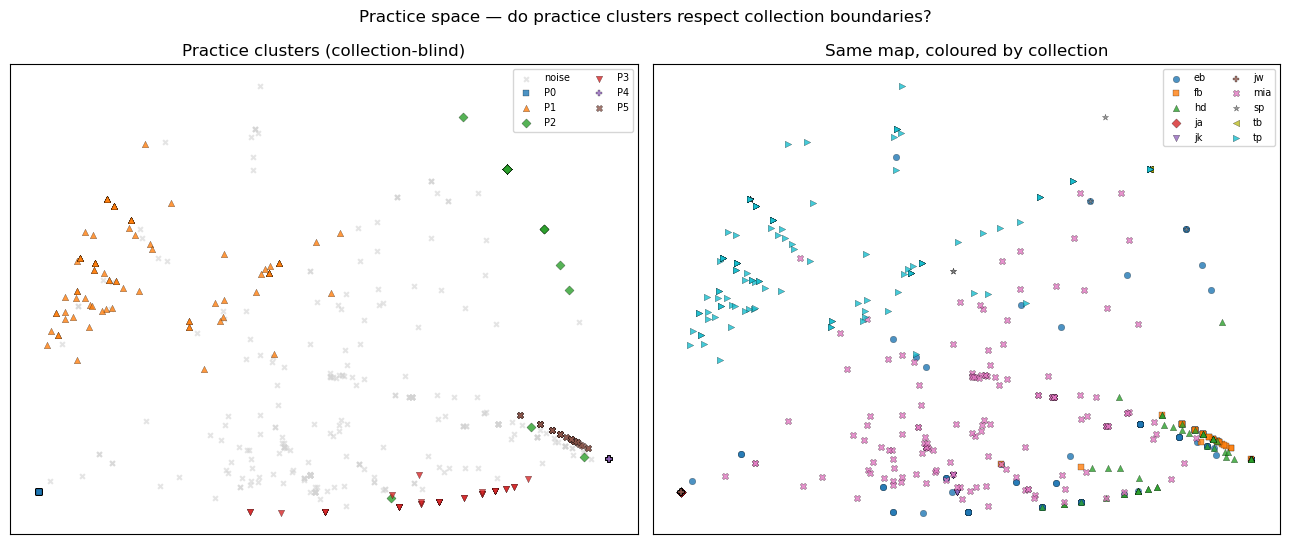

In [12]:
def pcoa(Dm, dims=2):
    """Classical (metric) MDS / principal coordinates — fast, deterministic."""
    n = Dm.shape[0]; J = np.eye(n) - np.ones((n,n))/n
    B = -0.5 * J @ (Dm**2) @ J
    w, v = np.linalg.eigh(B); order = np.argsort(-w)
    w, v = w[order][:dims], v[:, order][:, :dims]
    return v * np.sqrt(np.clip(w, 0, None))

import matplotlib.pyplot as plt
XY = pcoa(D, 2)
markers = ["o","s","^","D","v","P","X","*","<",">","h","p"]
fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
# left: by practice cluster (colour + marker, CVD-safe)
for k,lab in enumerate(sorted(set(labels))):
    m = labels==lab
    if lab==-1:
        ax[0].scatter(XY[m,0], XY[m,1], c="lightgrey", marker="x", s=12, label="noise", alpha=.6)
    else:
        ax[0].scatter(XY[m,0], XY[m,1], marker=markers[k%len(markers)], s=22,
                      label=f"P{lab}", alpha=.8, edgecolor="k", linewidth=.2)
ax[0].set_title("Practice clusters (collection-blind)"); ax[0].legend(fontsize=7, ncol=2)
# right: same points, coloured by collection
colls = sorted(set(records[i]["collection"] for i in samp))
for k,c in enumerate(colls):
    m = np.array([records[i]["collection"]==c for i in samp])
    ax[1].scatter(XY[m,0], XY[m,1], marker=markers[k%len(markers)], s=22,
                  label=c, alpha=.8, edgecolor="k", linewidth=.2)
ax[1].set_title("Same map, coloured by collection"); ax[1].legend(fontsize=7, ncol=2)
for a_ in ax: a_.set_xticks([]); a_.set_yticks([])
fig.suptitle("Practice space — do practice clusters respect collection boundaries?")
fig.tight_layout(); fig.savefig(VIS / f"practice-map_nls-merged-corpus_{TS}.png", dpi=140)
plt.show()

## Step 10 — Profiles and composition
Left: mean structural profile of each practice cluster (what each cluster *does*). Right: collection make-up of each cluster (colour + hatch, since the PI is colour-deficient).

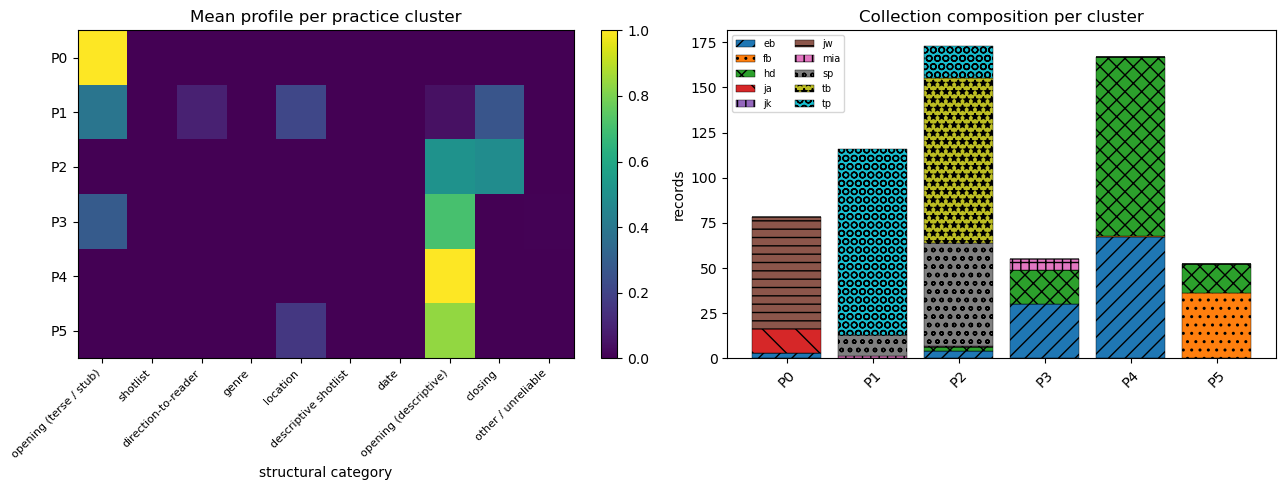

In [13]:
clu = [lab for lab in sorted(set(labels)) if lab!=-1]
prof_mat = np.vstack([np.mean([masked[samp[j]]["share"] for j in range(len(samp)) if labels[j]==lab], axis=0) for lab in clu])
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
im = ax[0].imshow(prof_mat, aspect="auto", cmap="viridis")
ax[0].set_xticks(range(len(sm.CONSOLIDATED_ORDER))); ax[0].set_xticklabels([sm.label_v2(l) for l in sm.CONSOLIDATED_ORDER], rotation=45, ha="right", fontsize=8)
ax[0].set_yticks(range(len(clu))); ax[0].set_yticklabels([f"P{l}" for l in clu])
ax[0].set_xlabel("structural category"); ax[0].set_title("Mean profile per practice cluster")
fig.colorbar(im, ax=ax[0], fraction=.046)
# stacked composition with hatching
colls = sorted(set(records[i]["collection"] for i in samp))
hatches = ["//","..","xx","\\","||","--","++","oo","**","OO"]
bottom = np.zeros(len(clu))
for k,c in enumerate(colls):
    vals = [sum(1 for j in range(len(samp)) if labels[j]==lab and records[samp[j]]["collection"]==c) for lab in clu]
    ax[1].bar(range(len(clu)), vals, bottom=bottom, label=c,
              hatch=hatches[k%len(hatches)], edgecolor="k", linewidth=.3)
    bottom += np.array(vals)
ax[1].set_xticks(range(len(clu))); ax[1].set_xticklabels([f"P{l}" for l in clu], rotation=45)
ax[1].set_ylabel("records"); ax[1].set_title("Collection composition per cluster"); ax[1].legend(fontsize=7, ncol=2)
fig.tight_layout(); fig.savefig(VIS / f"practice-profiles_nls-merged-corpus_{TS}.png", dpi=140)
plt.show()

## Step 11 — Secondary check: does collection still dominate? (demoted)

Not the headline, but worth one honest look. SM sequence similarity (Baker/Salway
continuity) and JS divergence, split into within- vs between-collection pairs. A
large gap means collection still structures practice strongly; a small gap means
practice varies as much within collections as between — the cross-collection signal.

JS divergence : within=0.274 between=0.299 gap=+0.025 (perm p=0.0010)
SM similarity : within=0.731 between=0.693


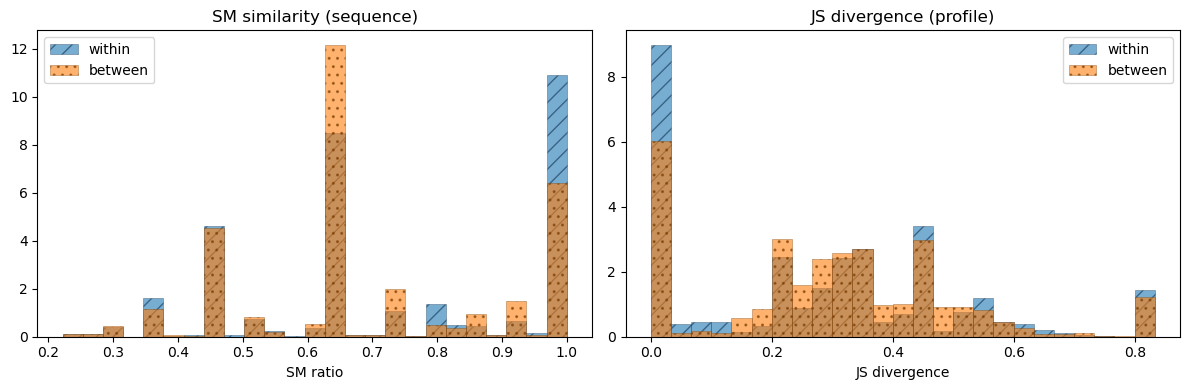

In [14]:
from difflib import SequenceMatcher
sub = samp[:SM_SUBSAMPLE]
# JS within/between from D
idxmap = {i:k for k,i in enumerate(samp)}
js_w, js_b, sm_w, sm_b = [],[],[],[]
for a_i in range(len(sub)):
    i=sub[a_i]; ci=records[i]["collection"]; si=" ".join(masked[i]["seq"])
    for b_i in range(a_i+1,len(sub)):
        j=sub[b_i]; same = ci==records[j]["collection"]
        d = D[idxmap[i], idxmap[j]]
        (js_w if same else js_b).append(d)
        r = SequenceMatcher(None, si, " ".join(masked[j]["seq"]), autojunk=False).ratio()
        (sm_w if same else sm_b).append(r)
js_w,js_b,sm_w,sm_b = map(np.array,(js_w,js_b,sm_w,sm_b))
obs = js_b.mean()-js_w.mean(); allp=np.concatenate([js_w,js_b]); nw=len(js_w)
perm=np.empty(N_PERMUTATIONS)
for t in range(N_PERMUTATIONS):
    np.random.shuffle(allp); perm[t]=allp[nw:].mean()-allp[:nw].mean()
pval=(np.sum(perm>=obs)+1)/(N_PERMUTATIONS+1)
print(f"JS divergence : within={js_w.mean():.3f} between={js_b.mean():.3f} gap={obs:+.3f} (perm p={pval:.4f})")
print(f"SM similarity : within={sm_w.mean():.3f} between={sm_b.mean():.3f}")
fig, ax = plt.subplots(1,2,figsize=(12,4))
for a_,(w,b,t,xl) in zip(ax, [(sm_w,sm_b,"SM similarity (sequence)","SM ratio"),
                              (js_w,js_b,"JS divergence (profile)","JS divergence")]):
    a_.hist(w,bins=25,density=True,alpha=.6,color="#1f77b4",hatch="//",edgecolor="#10324f",linewidth=.4,label="within")
    a_.hist(b,bins=25,density=True,alpha=.6,color="#ff7f0e",hatch="..",edgecolor="#7a3c00",linewidth=.4,label="between")
    a_.set_title(t); a_.set_xlabel(xl); a_.legend()
fig.tight_layout(); fig.savefig(VIS / f"within-between_nls-merged-corpus_{TS}.png", dpi=140); plt.show()

## Step 12 — How far did the method get? (honest assessment)

This cell summarises the test-case result in the terms the paper needs.

In [15]:
cross_n = len(cross)
biggest_cross = practice[(practice.cross_collection=="YES")].head(1)
print("METHODS-TEST SUMMARY")
print(f"- structural categories derived (data-driven, K={K}); collection-independence AMI={ami:.2f}")
print(f"- records sampled: {len(samp)};  practice clusters: {n_clusters};  unclustered: {noise:.0%}")
print(f"- collection-crossing clusters: {cross_n}/{n_clusters}")
if len(biggest_cross):
    bc = biggest_cross.iloc[0]
    print(f"- largest cross-collection practice cluster: {bc['cluster']} "
          f"(n={bc['size']}, {bc['collections']})")
print()
print("Reading: a non-trivial cluster count with collection-crossing members is")
print("evidence that the pipeline can approximate shared practice at scale. A high")
print("noise fraction is not failure — it marks records whose practice is idiosyncratic")
print("or too sparse to place, and bounds how far THIS representation reaches.")

METHODS-TEST SUMMARY
- structural categories derived (data-driven, K=10); collection-independence AMI=0.27
- records sampled: 901;  practice clusters: 6;  unclustered: 29%
- collection-crossing clusters: 6/6
- largest cross-collection practice cluster: P2 (n=173, tb:91, sp:57, tp:18, eb:4, hd:2, mia:1)

Reading: a non-trivial cluster count with collection-crossing members is
evidence that the pipeline can approximate shared practice at scale. A high
noise fraction is not failure — it marks records whose practice is idiosyncratic
or too sparse to place, and bounds how far THIS representation reaches.


## Next steps & caveats

1. **Human-label the categories** (`structure-categories_*.tsv`) and the practice
   clusters (`practice-clusters_*.tsv`) before any claim — check for the greedy-masking
   failure (genre/convention markers absorbed into a generic category; 2026-04-22 note).
2. **Tune HDBSCAN honestly.** `MIN_CLUSTER_SIZE` / `MIN_SAMPLES` change the noise
   fraction; report the setting and a sensitivity sweep, do not pick the value that
   maximises cross-collection clusters.
3. **Add the sequence dimension.** Practice is also *order*: cluster on edit/alignment
   distance over sequences as well as JS divergence over profiles, and compare.
4. **Scale beyond the sample** with MinHash-LSH blocking; the JS step already scales
   via `pdist`.
5. **The hypothesis is real; the method is on trial.** Report what does *not* cluster
   and where collection still dominates as openly as the cross-collection wins. The
   contribution is an honest measure of how far computation can approximate
   transmitted practice — not a forced confirmation.